# Setup

In [6]:
#TODO: Rename repo to cghd

In [40]:
# load data
import os
from dotenv import find_dotenv, load_dotenv
import pandas as pd
from huggingface_hub import hf_hub_download
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches
import pickle as pkl

In [8]:
load_dotenv(find_dotenv(usecwd=True))
data_path = os.environ["DATA_PATH"]

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
from huggingface_hub import snapshot_download

download = snapshot_download(
    repo_id="lowercaseonly/cghd",
    repo_type="dataset",
    local_dir=data_path,
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8207 files:   0%|          | 0/8207 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/lowercaseonly/cghd/44a246d1dc41758ff46c26bd69dccd43d2055eba/drafter_22%2Fannotations%2FC253_D2_P4.xml?%2Fdatasets%2Flowercaseonly%2Fcghd%2Fresolve%2F44a246d1dc41758ff46c26bd69dccd43d2055eba%2Fdrafter_22%2Fannotations%2FC253_D2_P4.xml=&etag=%22ab21ca9ba41e0ce105f87dbda4637c681f7d77ae%22
Rate limited. Waiting 37.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/lowercaseonly/cghd/44a246d1dc41758ff46c26bd69dccd43d2055eba/drafter_22%2Fannotations%2FC253_D2_P3.xml?%2Fdatasets%2Flowercaseonly%2Fcghd%2Fresolve%2F44a246d1dc41758ff46c26bd69dccd43d2055eba%2Fdrafter_22%2Fannotations%2FC253_D2_P3.xml=&etag=%22e45e87169f15c22c94636ed5c7de65cc9e0184fb%22
Rate limited. Waiting 37.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/lowercaseonly/cghd/resolve/44a246d1dc41758ff46c26bd69dcc

In [11]:
class Samples:
    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.image_suffixes = {".jpg", ".jpeg", ".png"}

    def _index(self, folder, suffixes):
        if not folder.is_dir():
            return {}
        return {
            path.stem: path
            for path in folder.iterdir()
            if not path.name.startswith(".") and path.suffix.lower() in suffixes
        }

    def __iter__(self):
        drafters = sorted(
            (path for path in self.data_dir.glob("drafter_*") if path.is_dir()),
            key=lambda path: int(path.name.split("_", 1)[1]),
        )
        for drafter in drafters:
            images = self._index(drafter / "images", self.image_suffixes)
            segments = self._index(drafter / "segmentation", self.image_suffixes)
            annotations = self._index(drafter / "annotations", {".xml"})
            for stem, image_path in sorted(images.items()):
                yield image_path, segments.get(stem), annotations.get(stem)

In [12]:
import xml.etree.ElementTree as ET
from PIL import Image

def _load_annotation(annotation_path: Path | None):
    if annotation_path is None:
        return ()

    root = ET.parse(annotation_path).getroot()
    objects = []
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        bbox = (
            int(box.findtext("xmin")),
            int(box.findtext("ymin")),
            int(box.findtext("xmax")),
            int(box.findtext("ymax")),
        )
        objects.append((obj.findtext("name"), bbox))
    return tuple(objects)


def sample_processor(sample: tuple[Path, Path | None, Path | None], segmentation_only: bool = False):
    if segmentation_only and sample[1] is None:
        return None

    image = Image.open(sample[0])
    segment = Image.open(sample[1]) if sample[1] is not None else None
    annotation = _load_annotation(sample[2])
    return image, segment, annotation



In [13]:
# sample 20 from Samples randomly
import random
sampled = random.sample(list(Samples(data_path)), 20)
for sample in sampled:
    processed = sample_processor(sample, segmentation_only=False)
    if processed is None:
        continue
    image, segment, annotation = processed
    print(image, segment, annotation)

<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=3024x2971 at 0x7FC5B0489940> None (('text', (1078, 1450, 1166, 1493)), ('junction', (991, 1517, 1021, 1547)), ('text', (254, 1261, 332, 1296)), ('text', (1507, 1546, 1572, 1575)), ('text', (1044, 681, 1119, 719)), ('text', (867, 1901, 945, 1938)), ('text', (1234, 1006, 1327, 1047)), ('text', (464, 2404, 513, 2443)), ('text', (1661, 807, 1718, 843)), ('text', (975, 748, 1030, 792)), ('text', (549, 818, 602, 856)), ('text', (1907, 609, 2009, 652)), ('text', (1769, 1195, 1854, 1229)), ('text', (2772, 2410, 2827, 2470)), ('text', (328, 855, 413, 890)), ('text', (445, 826, 519, 869)), ('text', (1906, 1405, 1933, 1440)), ('text', (1145, 886, 1177, 917)), ('text', (1810, 2025, 1932, 2070)), ('text', (1009, 936, 1052, 974)), ('text', (259, 1953, 322, 1987)), ('junction', (1002, 1682, 1030, 1710)), ('junction', (648, 920, 678, 950)), ('text', (795, 2223, 858, 2261)), ('text', (2171, 2080, 2288, 2120)), ('text', (1769, 1336, 1848, 1367)), ('

In [14]:
samples = [image for image in Samples(data_path)] # iterates over all images in the data path
process = lambda list_of_samples: (sample_processor(image) for image in list_of_samples) # processes each image in the list of samples with actual image objects
processed_samples = list(process(samples)) # list of all processed images

## Class Distribution

In [15]:
# Class Distribution
from cProfile import label
from collections import Counter


boxes_labels = [sample[2] for sample in processed_samples] # list of class labels for all processed images
box_label_flat = [label for box_labels in boxes_labels for label in box_labels] # From 3D list to 1D list
labels_only = [label[0] for label in box_label_flat] # extract only the label part from each box label tuple
# count unique labels
label_counts = Counter(labels_only)
print(label_counts)


Counter({'text': 91238, 'junction': 79594, 'resistor': 14488, 'terminal': 11297, 'crossover': 10188, 'capacitor.unpolarized': 5841, 'gnd': 5565, 'diode': 3922, 'transistor.bjt': 3694, 'capacitor.polarized': 2227, 'switch': 2184, 'inductor': 1976, 'integrated_circuit': 1506, 'vss': 1354, 'diode.light_emitting': 1252, 'resistor.adjustable': 1076, 'transistor.fet': 977, 'and': 860, 'voltage.battery': 773, 'operational_amplifier': 760, 'explanatory': 610, 'diode.zener': 609, 'not': 496, 'transformer': 483, 'or': 440, 'thyristor': 415, 'speaker': 410, 'magnetic': 364, 'integrated_circuit.voltage_regulator': 362, 'voltage.dc': 335, 'lamp': 301, 'voltage.ac': 300, 'integrated_circuit.ne555': 262, 'nand': 228, 'fuse': 226, 'transistor.photo': 193, 'socket': 184, 'varistor': 184, 'probe': 184, 'optocoupler': 162, 'xor': 162, 'optical': 127, 'inductor.ferrite': 120, 'crystal': 112, 'motor': 108, 'triac': 98, 'relay': 89, 'capacitor.adjustable': 88, 'microphone': 72, 'probe.current': 72, 'resisto

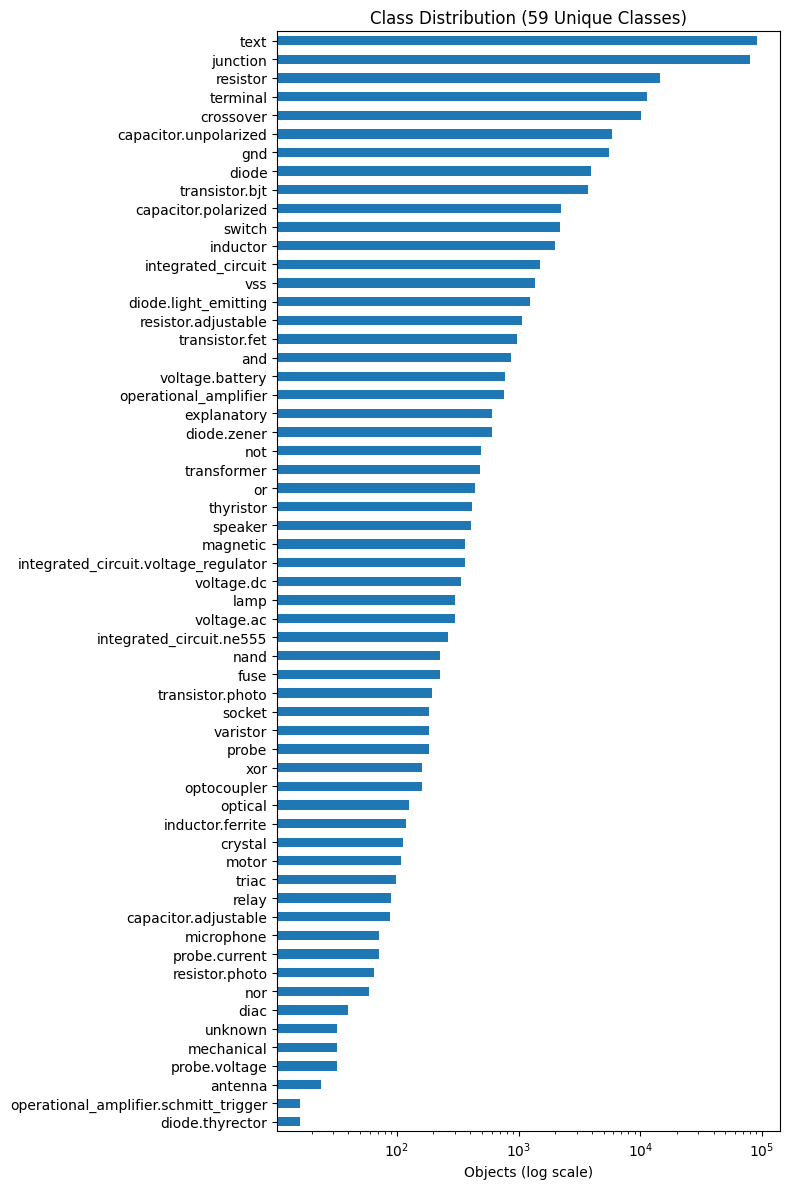

In [16]:
image_bounding_boxes = [sample[2] for sample in processed_samples] # list of bounding boxes for all processed images
# Visualize Class Distribution
counts = (
    pd.Series([label for boxes in image_bounding_boxes for label, _ in boxes])
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 12))
ax.set_title(f'Class Distribution ({len(counts)} Unique Classes)')
counts.plot.barh(ax=ax, logx=True) #logx gives us a logarithmic scale for better visualization of class distribution (relative frequencies)
ax.set_xlabel("Objects (log scale)")
ax.set_ylabel("")
fig.tight_layout()

In [17]:
## What percentage of our bounding boxes are the text class relative to the total number of bounding boxes?
text_counts = [sample[2] for sample in processed_samples if "text" in [label for label, _ in sample[2]]]
text_percentage = len(text_counts) / len(processed_samples)
print(f"Percentage of bounding boxes that are text: {text_percentage:.2%}")

Percentage of bounding boxes that are text: 76.94%


Given our objective here is just to demo, lets take the labeled classes, excluding text as that shouldn't be the focus for the HGMCC task, its about analysing curcits and their connections.

In [18]:
# total amount of bounding boxes in the processed samples
total_bounding_boxes = sum(len(boxes) for _, _, boxes in processed_samples)

In [19]:
processed_samples = [
    (
        image,
        segment,
        tuple((label, box) for label, box in boxes if label != "text"),
    )
    for image, segment, boxes in processed_samples
]


# remove any boxes that have no remaining labels
processed_samples = [
    (image, segment, boxes)
    for image, segment, boxes in processed_samples
    if boxes
]

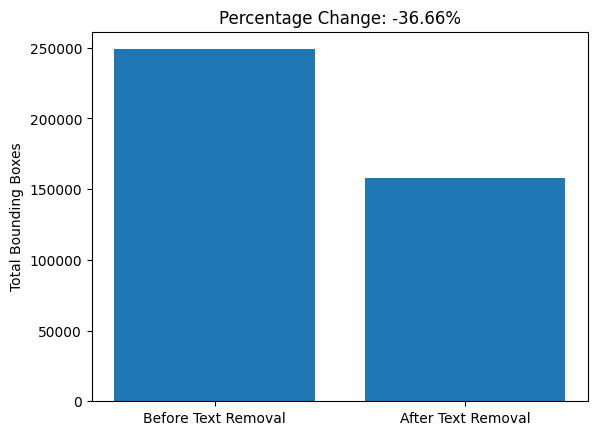

In [20]:
total_bounding_boxes_post_text_removal = sum(len(boxes) for _, _, boxes in processed_samples)

# plot total_bounding_boxes
import matplotlib.pyplot as plt

plt.bar(["Before Text Removal", "After Text Removal"], [total_bounding_boxes, total_bounding_boxes_post_text_removal])
# add percentage change
percentage_change = (total_bounding_boxes_post_text_removal - total_bounding_boxes) / total_bounding_boxes * 100
plt.title(f"Percentage Change: {percentage_change:.2f}%")
plt.ylabel("Total Bounding Boxes")
plt.show()

In [21]:
dataset_size = len(processed_samples) # number of labeled samples after image removal
print(dataset_size)

3293


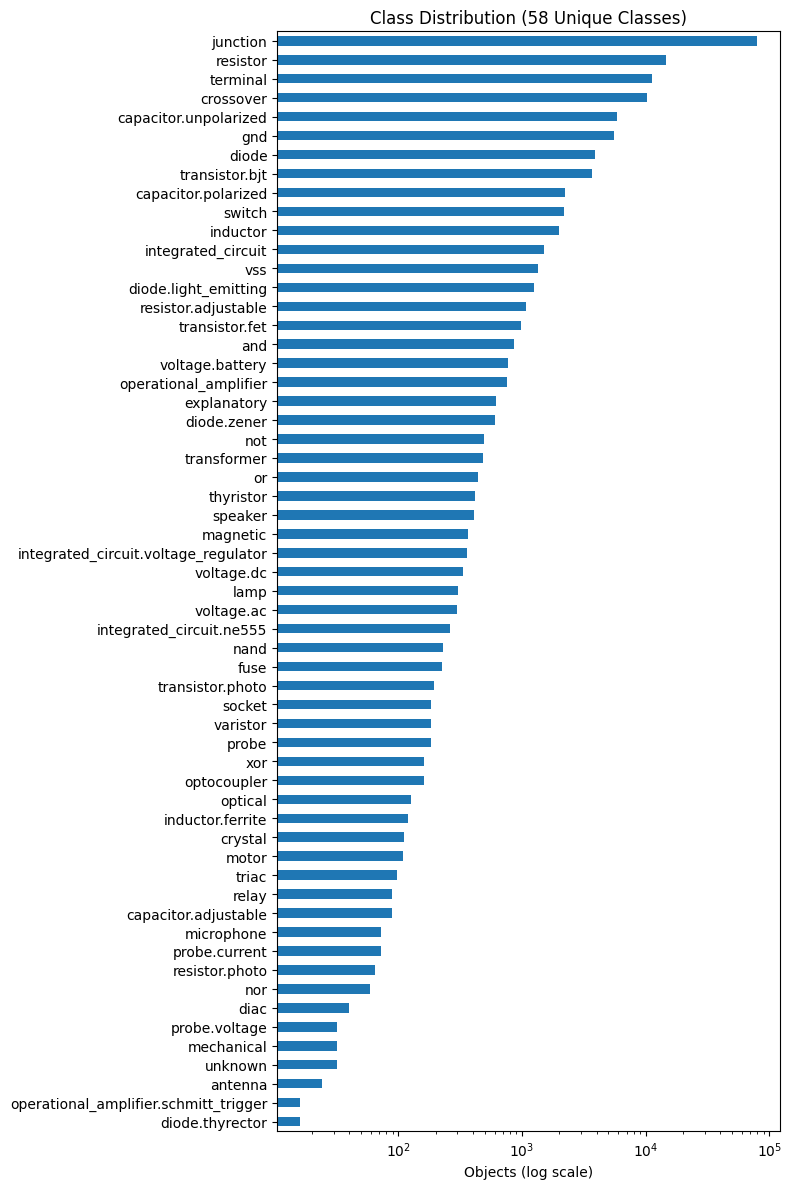

In [22]:
# updated class distribution plot
image_bounding_boxes = [sample[2] for sample in processed_samples] # list of bounding boxes for all processed images
# Visualize Class Distribution
counts = (
    pd.Series([label for boxes in image_bounding_boxes for label, _ in boxes])
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 12))
ax.set_title(f'Class Distribution ({len(counts)} Unique Classes)')
counts.plot.barh(ax=ax, logx=True) #logx gives us a logarithmic scale for better visualization of class distribution (relative frequencies)
ax.set_xlabel("Objects (log scale)")
ax.set_ylabel("")
fig.tight_layout()

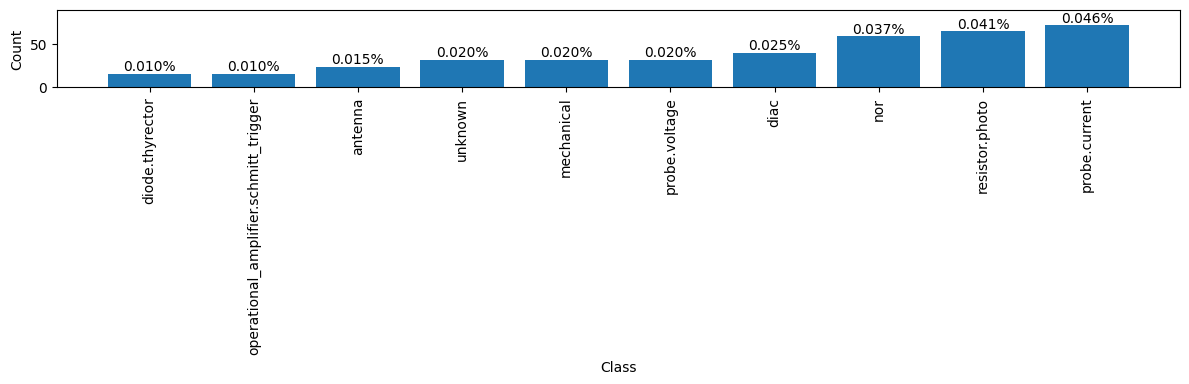

In [23]:
# plot the lowest frequency classes distribution, with percentages on top of each bar
class_counts = (
    pd.Series([label for _, _, boxes in processed_samples for label, _ in boxes])
    .value_counts()
    .sort_values()
)
lowest = class_counts.head(10)
total_boxes = class_counts.sum()

plt.figure(figsize=(12, 4))
plt.bar(lowest.index, lowest.values)
for index, (_, count) in enumerate(lowest.items()):
    percentage = count / total_boxes * 100
    plt.text(index, count, f"{percentage:.3f}%", ha="center", va="bottom")
plt.xticks(rotation=90)
plt.ylim(0, lowest.max() * 1.25)
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

As we have removed text labels from the bounding boxes, we can observe the change in the total number of bounding boxes before and after this removal of around `36.66%`. This is significant and but still leaves over `150,000` bounding boxes for modeling and the removal of text will allow backpropagation, and thus our weights, to be updated with a focus on the remaining relevant labels.

## Class distribution summary:

There is significant class imbalance in the dataset, with some classes having many more instances than others. This will need to be taken into consideration during model training to ensure that the model does not become biased towards the more frequent classes. We removed text labels from the bounding boxes, which should help mitigate the most severe cases of bias. However, given the overall distribution, additional techniques such as class weighting or oversampling may still be necessary to achieve balanced model performance.

There are 58 unique classes in the dataset after removing text labels from the bounding boxes. Some of which represent about 0.01% of the total instances. This again, highlights the need for careful handling of class imbalance during model training.

## Image Properties

In [24]:

image_heights = [image[0].height for image in processed_samples] # list of heights of all processed images
image_widths = [image[0].width for image in processed_samples] # list of widths of all processed images
assert len(image_heights) == len(image_widths), "Mismatch between number of image heights and widths"

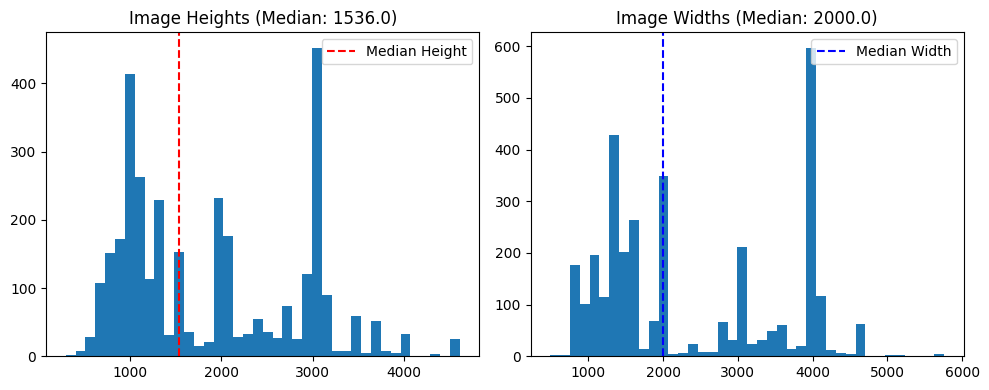

Median Height: 1536.0
Median Width: 2000.0


In [25]:
median_height = np.median(image_heights)
median_width = np.median(image_widths)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(image_heights, bins=40)
axes[0].axvline(median_height, color='r', linestyle='--', label='Median Height')
axes[1].hist(image_widths, bins=40)
axes[1].axvline(median_width, color='b', linestyle='--', label='Median Width')
axes[0].set_title(f'Image Heights (Median: {median_height})')
axes[1].set_title(f'Image Widths (Median: {median_width})')
axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

print("Median Height:", median_height)
print("Median Width:", median_width)

Clearly their a huge amount of diversity in the image dimensions. The histograms above help visualize this variation, and the median lines provide a reference for the typical image size.

We will need to scale or resize the images appropriately before feeding them into any machine learning models to ensure consistent input dimensions.

In [26]:
print("Number of Images:", len(processed_samples))

Number of Images: 3293


A reasonable amount of samples are present, this will be good for fighting overfitting in our machine learning models.

1 : 83.54%
0 : 7.14%
6 : 6.19%
8 : 2.28%
3 : 0.85%


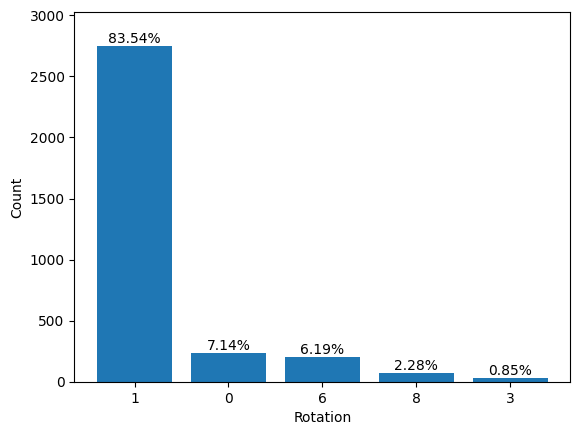

In [27]:
# Amount of images with a rotation, split by orientation, with percentages on top of each bar
rotations = [image[0].getexif().get(274, 1) for image in processed_samples]
rotation_counts = Counter(rotations)

labels = [str(rotation) for rotation in rotation_counts.keys()]
counts = list(rotation_counts.values())
plt.bar(labels, counts)
for index, (rotation, count) in enumerate(rotation_counts.items()):
    percentage = count / len(processed_samples) * 100
    plt.text(index, count, f"{percentage:.2f}%", ha="center", va="bottom")
    print(f"{rotation} : {percentage:.2f}%")
plt.ylim(0, max(counts) * 1.1)
plt.xlabel("Rotation")
plt.ylabel("Count")
plt.show()


these rotations from EXIF are a bit odd. EXIF orientations go from 1 to 8, representing different rotation and mirroring states of the image.

`0` means an orientation tag but its undefined

`1` represents the normal orientation (no rotation or mirroring)

`2` flipped left to right (mirrored horizontally).

`3` rotated 180 degrees.

`4` flipped top to bottom (mirrored vertically).

`5` rotated 90 degrees clockwise and flipped left to right.

`6` rotated 90 degrees clockwise.

`7` rotated 90 degrees counterclockwise and flipped left to right.

`8` rotated 90 degrees counterclockwise.

Most of our images have an EXIF orientation of `1`, meaning they are in the normal orientation without any rotation or mirroring. The next largest group is `0`, which is not one of the standard 1–8 orientations. We will still need to handle the other orientations correctly when processing the images into the model datasets.

## Overlay Images with their bounding boxes (Sample review)

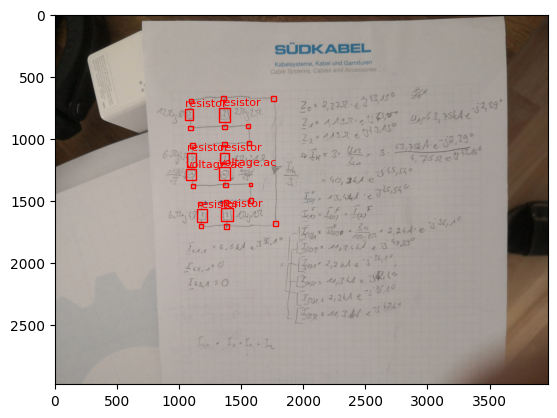

In [28]:
import matplotlib.patches as patches
from PIL import ImageOps
def overlay_bounding_boxes(image, bounding_boxes):
    """
    Overlay bounding boxes on an image.

    Parameters:
    - image: The input image as a PIL image or NumPy array.
    - bounding_boxes: Annotations as (class_name, (x_min, y_min, x_max, y_max)).

    Returns:
    - The image with bounding boxes overlaid.
    """

    image = ImageOps.exif_transpose(image)
    skip_labels = {"junction", "terminal", "crossover"} # clean up the labels for better visualization

    fig, ax = plt.subplots(1)
    ax.imshow(image)

    for label, (x_min, y_min, x_max, y_max) in bounding_boxes:
        rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(rect)
        if label not in skip_labels:
            ax.text(x_min, y_min, label, color='r', fontsize=8, va='bottom')

    plt.show()

render = lambda idx: overlay_bounding_boxes(processed_samples[idx][0], processed_samples[idx][2])
render(0)

exif is an abbreviation for Exchangeable Image File Format, which is a standard for storing metadata in image files, such as the camera settings, date and time, and GPS location.

The bounding boxes were drawn on the upright photo, while some files are stored rotated. `overlay_bounding_boxes` applies `exif_transpose` to the one image being drawn, so the pixels match the boxes without decoding the whole dataset.

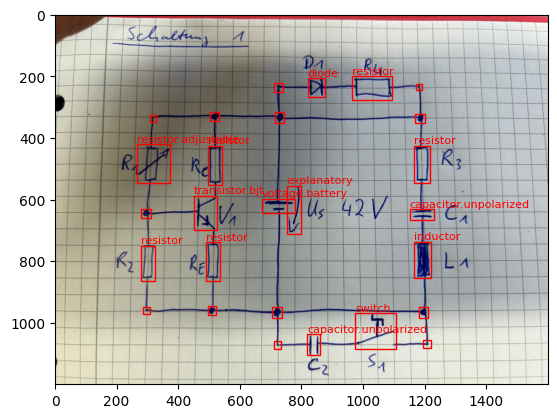

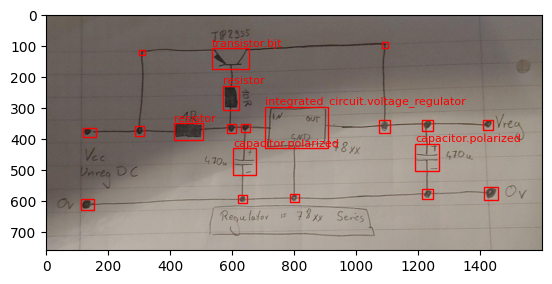

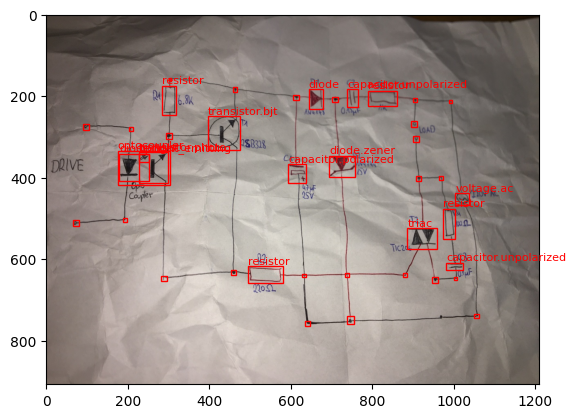

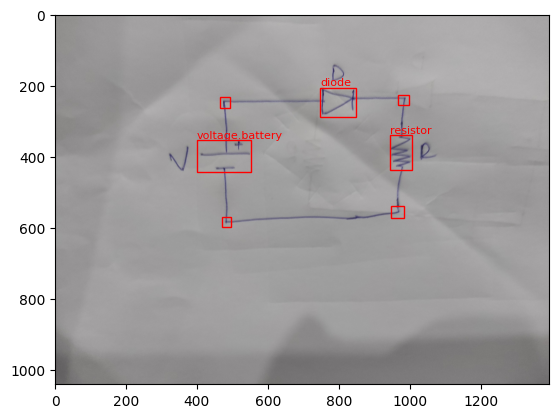

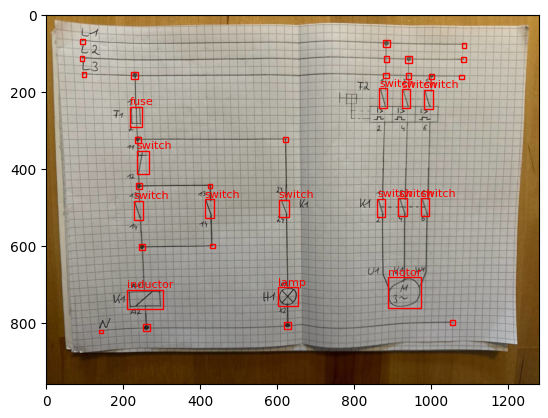

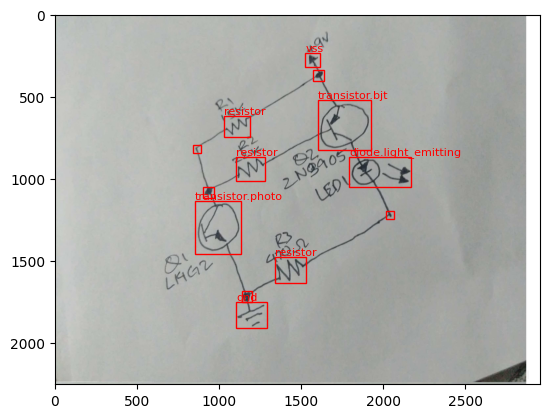

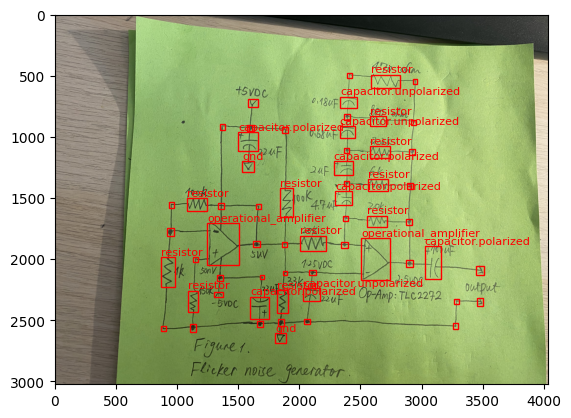

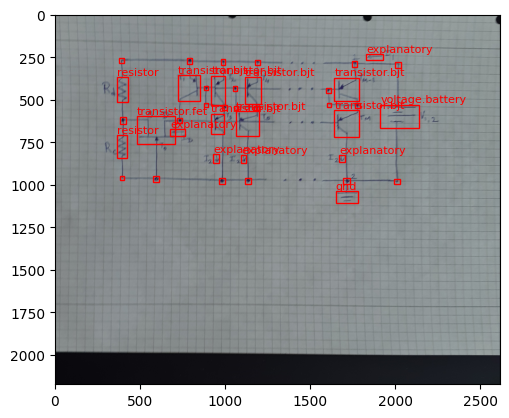

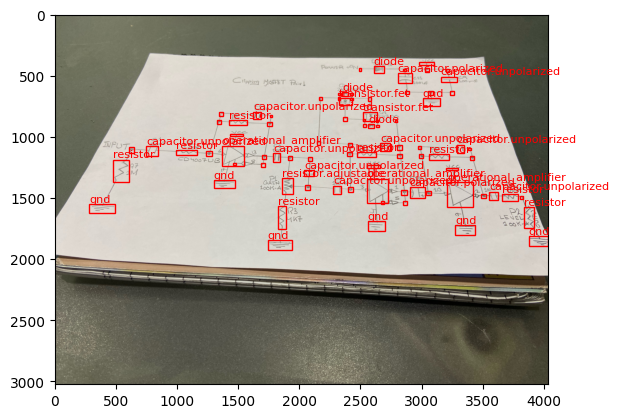

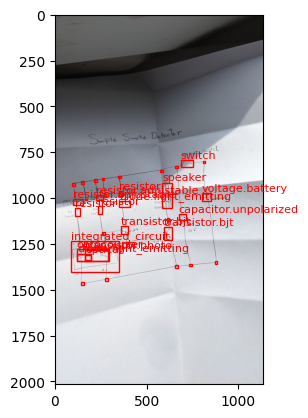

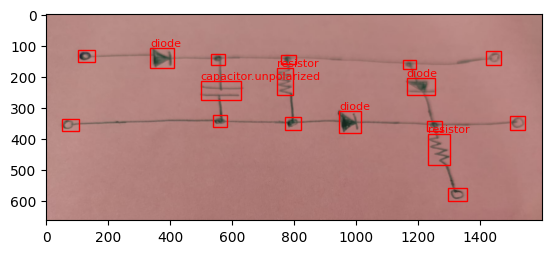

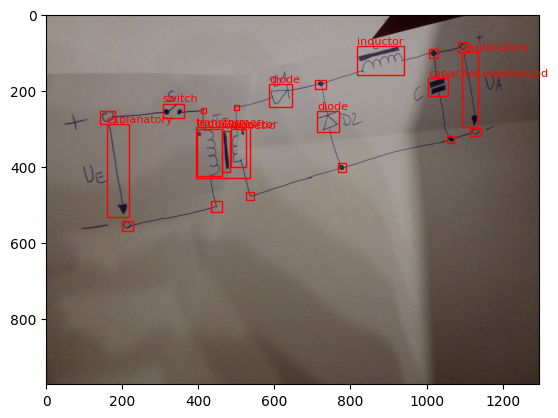

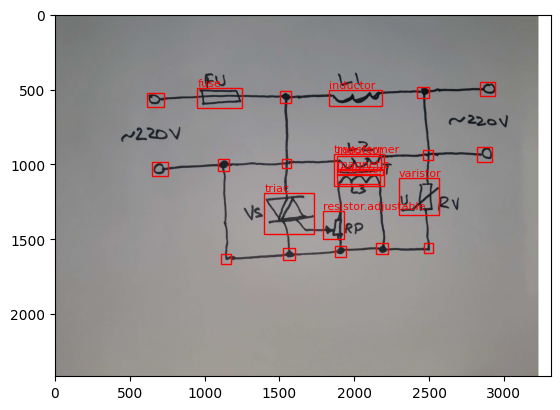

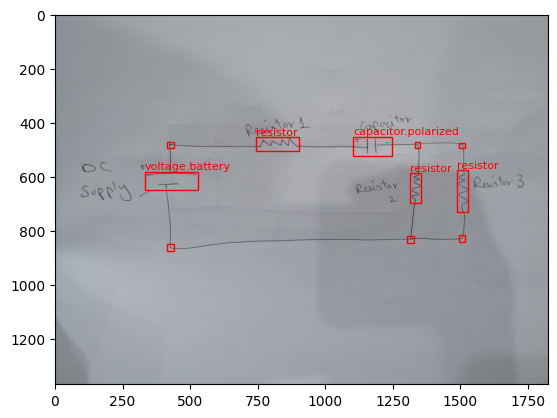

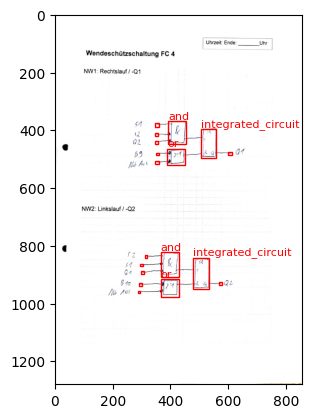

In [29]:
sample_indices = random.sample(range(len(processed_samples)), 15)
for idx in sample_indices:
    render(idx)

A sample review shows most of the bounding boxes are correctly aligned with the objects in the images and a generally good quality of annotations across various resolutions, angles, orientations and lighting conditions.

It is clear from this sample review that the dataset contains images at many more different resolutions, angles, orientations, and lighting conditions than i originally anticipated. This diversity will likely make the model more robust (less prone to overfitting) and better at generalizing to new, unseen data. However, it also means that the model will need to be selected with care to handle this multi-factor variability effectively.

## box sizes relative to the image.

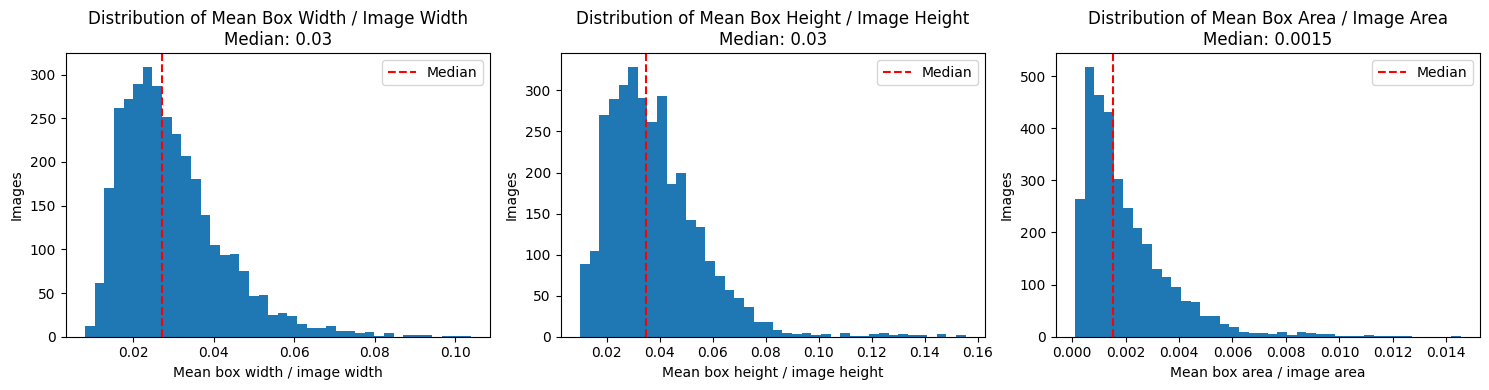

In [30]:
def oriented_size(image):
    # Orientations 5-8 swap width and height. Read the tag only, so the pixels stay unloaded.
    orientation = image.getexif().get(274, 1)
    if orientation in (5, 6, 7, 8):
        return image.height, image.width
    return image.width, image.height

box_width_ratios = []
box_height_ratios = []
box_area_ratios = []
for image, _, boxes in processed_samples:
    widths = [xmax - xmin for _, (xmin, ymin, xmax, ymax) in boxes]
    heights = [ymax - ymin for _, (xmin, ymin, xmax, ymax) in boxes]
    areas = [width * height for width, height in zip(widths, heights)]
    image_width, image_height = oriented_size(image)
    box_width_ratios.append(np.mean(widths) / image_width)
    box_height_ratios.append(np.mean(heights) / image_height)
    box_area_ratios.append(np.mean(areas) / (image_width * image_height))

median_box_width_ratio = np.median(box_width_ratios)
median_box_height_ratio = np.median(box_height_ratios)
median_box_area_ratio = np.median(box_area_ratios)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(box_width_ratios, bins=40)
axes[0].set_title("Distribution of Mean Box Width / Image Width\nMedian: {:.2f}".format(median_box_width_ratio))
axes[0].axvline(median_box_width_ratio, color="r", linestyle="--", label="Median")
axes[0].set_xlabel("Mean box width / image width")
axes[0].set_ylabel("Images")
axes[0].legend()

axes[1].hist(box_height_ratios, bins=40)
axes[1].set_title("Distribution of Mean Box Height / Image Height\nMedian: {:.2f}".format(median_box_height_ratio))
axes[1].axvline(median_box_height_ratio, color="r", linestyle="--", label="Median")
axes[1].set_xlabel("Mean box height / image height")
axes[1].set_ylabel("Images")
axes[1].legend()

axes[2].hist(box_area_ratios, bins=40)
axes[2].set_title("Distribution of Mean Box Area / Image Area\nMedian: {:.4f}".format(median_box_area_ratio))
axes[2].axvline(median_box_area_ratio, color="r", linestyle="--", label="Median")
axes[2].set_xlabel("Mean box area / image area")
axes[2].set_ylabel("Images")
axes[2].legend()

fig.tight_layout()

our bounding boxes relative to the overall image resolution are small. These plots are the mean box size per image. Height and width are mostly around 2–5% of the image, with a median of 3%, and tails out to about 10% of the width and 16% of the height.

When considering area, the median is about 0.15%, but it's driven up by a few larger boxes. 0.09% looks like the more typical value for most images.

Outliers clearly exist here with some images taking up a much larger portion of the image area than typical in terms of all 3 considerations: height, width, and area.

So our usual annotation boxes are relatively small compared to the overall image area, and this is true for most of our images.

## Count objects / bounding boxes per image

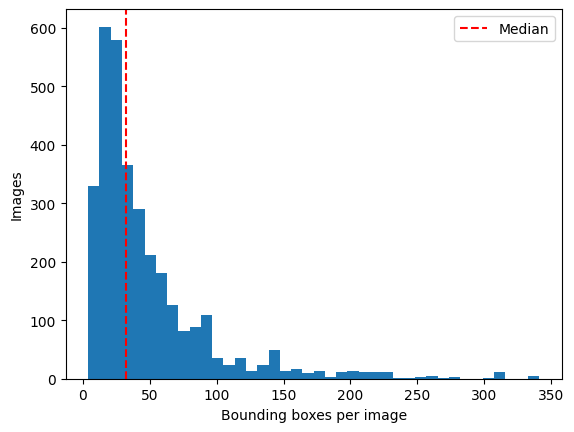

Median boxes per image: 32.0
Mean boxes per image: 47.87306407531127


In [31]:
objects_per_image = [len(boxes) for _, _, boxes in processed_samples]
median_objects = np.median(objects_per_image)

plt.hist(objects_per_image, bins=40)
plt.axvline(median_objects, color="r", linestyle="--", label="Median")
plt.xlabel("Bounding boxes per image")
plt.ylabel("Images")
plt.legend()
plt.show()

print("Median boxes per image:", median_objects)
print("Mean boxes per image:", np.mean(objects_per_image))

Theres clearly quite a few objects in our average image. With a median average of `32` and a mean average `48` per image, it suggests that our dataset contains a substantial number of objects, which could provide rich information for training our object classification models.

Some of our images contain a particularly high number of objects, which could indicate complex scenes or crowded environments. This variability in object count across images might help our models learn to generalize better across different scenarios.

## How often do bounding boxes overlap

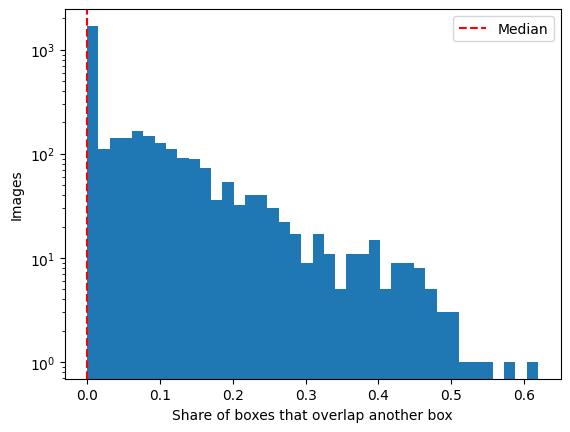

Images with at least one overlap: 1630 / 3293
Boxes that overlap another box: 10768 / 157646
Median share of overlapping boxes per image: 0.0


In [32]:
def boxes_overlap(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    return ax1 < bx2 and ax2 > bx1 and ay1 < by2 and ay2 > by1

overlap_fractions = []
overlapping_boxes = 0
total_boxes = 0
images_with_overlap = 0

for _, _, boxes in processed_samples:
    rects = [box for _, box in boxes]
    hits = 0
    for i, rect in enumerate(rects):
        if any(boxes_overlap(rect, other) for j, other in enumerate(rects) if i != j):
            hits += 1
    total_boxes += len(rects)
    overlapping_boxes += hits
    images_with_overlap += hits > 0
    overlap_fractions.append(hits / len(rects))

median_overlap = np.median(overlap_fractions)

# add log scale
plt.hist(overlap_fractions, bins=40, log=True)
plt.axvline(median_overlap, color="r", linestyle="--", label="Median")
plt.xlabel("Share of boxes that overlap another box")
plt.ylabel("Images")
plt.legend()
plt.show()

print("Images with at least one overlap:", images_with_overlap, "/", len(processed_samples))
print("Boxes that overlap another box:", overlapping_boxes, "/", total_boxes)
print("Median share of overlapping boxes per image:", median_overlap)

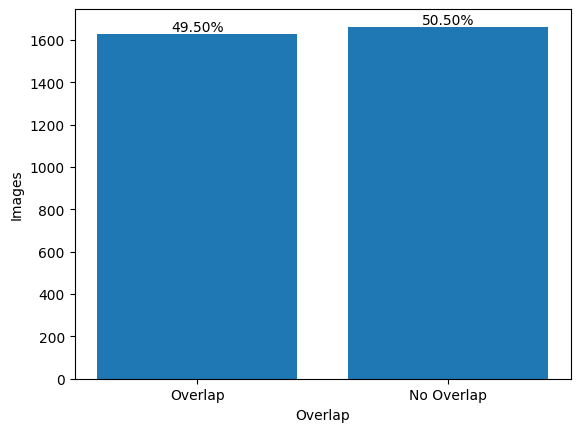

In [33]:
# plot images with overlap vs no overlap in a bar chart
plt.bar(["Overlap", "No Overlap"], [images_with_overlap, len(processed_samples) - images_with_overlap])
plt.xlabel("Overlap")
plt.ylabel("Images")
for index, (overlap, count) in enumerate(zip([images_with_overlap, len(processed_samples) - images_with_overlap], [images_with_overlap, len(processed_samples) - images_with_overlap])):
    percentage = count / len(processed_samples) * 100
    plt.text(index, count, f"{percentage:.2f}%", ha="center", va="bottom")
plt.show()


There doesn't seem to be too much overlap between the bounding boxes in our dataset. Most of the boxes are relatively small and distinct, which suggests that our annotations are well-separated and focused on individual objects rather than large, overlapping regions. This stands to reason given these are curcuit diagrams, where each component is typically isolated and clearly defined.

However, there is overlap in about half of the images, which may occur in areas where components are closely packed or interconnected. this overlap is limited with the most serve cases being around `0.6` of that image's boxes. Overall, the dataset appears to have well-defined and mostly non-overlapping bounding boxes, which should facilitate accurate object detection and classification.

## box validity (Nearly all bounding boxes fit within their images)

This code does a few checks:

- The box has no area if xmax is less than or equal to xmin, or ymax is less than or equal to ymin. Those are counted as empty or inverted.
- A box with area still fails if xmin or ymin is negative, or if xmax or ymax runs past the image width or height. Those are counted as outside the image.
- A box that passes both checks is counted as inside the image.
 - An image is counted as invalid if any one of its boxes fails either check.

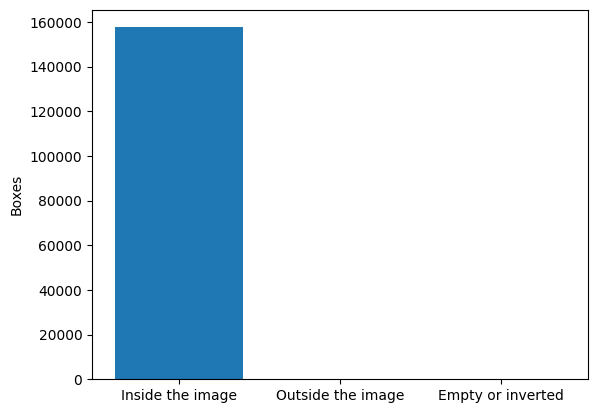

Boxes inside the image: 157644
Boxes outside the image: 2
Empty or inverted boxes: 0
Images with an invalid box: 2 / 3293


In [34]:
inside = 0
outside = 0
empty = 0
images_with_invalid = 0
boxes_to_remove = []

for image, _, boxes in processed_samples:
    image_width, image_height = oriented_size(image)
    invalid_here = False
    remove = set()
    for index, (_, (xmin, ymin, xmax, ymax)) in enumerate(boxes):
        if xmax <= xmin or ymax <= ymin:
            empty += 1
            invalid_here = True
            remove.add(index)
        elif xmin < 0 or ymin < 0 or xmax > image_width or ymax > image_height:
            outside += 1
            invalid_here = True
            remove.add(index)
        else:
            inside += 1
    images_with_invalid += invalid_here
    boxes_to_remove.append(remove)

plt.bar(["Inside the image", "Outside the image", "Empty or inverted"], [inside, outside, empty])
plt.ylabel("Boxes")
plt.show()

print("Boxes inside the image:", inside)
print("Boxes outside the image:", outside)
print("Empty or inverted boxes:", empty)
print("Images with an invalid box:", images_with_invalid, "/", len(processed_samples))

In [35]:
processed_samples = [
    (
        image,
        segment,
        tuple(box for index, box in enumerate(boxes) if index not in remove),
    )
    for (image, segment, boxes), remove in zip(processed_samples, boxes_to_remove)
]
processed_samples = [
    (image, segment, boxes)
    for image, segment, boxes in processed_samples
    if boxes
]

Looks like theirs just two invalid bounding boxes that are outside the image boundaries.

# Summary

This is a demo for the HGMCC task: analysing circuits and their connections. Text is left out, because it is not the focus.

Removing text drops about `36.66%` of the boxes and still leaves over `150,000`. Training can then update on the remaining labels. After that removal there are 58 classes, and some are about `0.01%` of instances. Imbalance is still large, so class weighting or oversampling may be needed. (2)

Image sizes vary a lot, so inputs need one consistent size. There are enough samples to help against overfitting. A typical image holds many objects: median `32`, mean `48`, and some images are much more crowded. That spread should help the model generalise. (1)

Most images have EXIF orientation `1`. Boxes were drawn on the upright photo, and some files are stored rotated, so the other orientations still need handling when images go into the model data.

Boxes are small relative to the image. Mean height and width are mostly `2–5%` of the image, median `3%`, with tails to about `10%` of the width and `16%` of the height. Area is typically about `0.09%`, the `0.15%` median is pulled up by a few larger boxes. Overlap is limited for a given box, and the worst images have about `0.6` of their boxes overlapping. Only two boxes sit outside the image.

A sample review shows the boxes mostly line up, across many resolutions, angles, orientations, and lighting conditions. That variety should make the model more robust, and the model still needs to be chosen to handle it.

## Coordinate location

Check the coordinate location

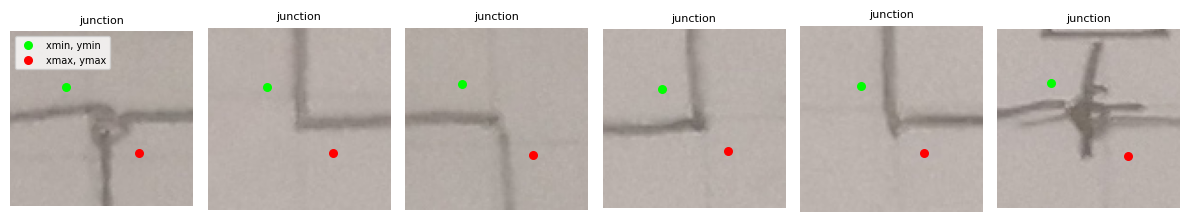

junction 1341 654 1381 690


In [36]:
image, _, boxes = processed_samples[0]
image = ImageOps.exif_transpose(image)
shown = boxes[:6]

fig, axes = plt.subplots(1, len(shown), figsize=(12, 3))
for ax, (label, (xmin, ymin, xmax, ymax)) in zip(axes, shown):
    pad = 30
    left, top = max(xmin - pad, 0), max(ymin - pad, 0)
    crop = image.crop((left, top, xmax + pad, ymax + pad))
    ax.imshow(crop)
    ax.scatter(xmin - left, ymin - top, c="lime", s=30, label="xmin, ymin")
    ax.scatter(xmax - left, ymax - top, c="red", s=30, label="xmax, ymax")
    ax.set_title(label, fontsize=8)
    ax.axis("off")

axes[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

label, (xmin, ymin, xmax, ymax) = shown[0]
print(label, xmin, ymin, xmax, ymax)

DETR requires center box coordinates, so we need to convert the corner box coordinates to center box coordinates

## Export data

In [37]:
# export paths and boxes; the image files are already in the data directory
data_dir = Path(data_path) # data directory from the DATA_PATH environment variable
exported = [
    (
        str(Path(image.filename).relative_to(data_dir)), # path inside the data directory (path is after data_dir)
        str(Path(segment.filename).relative_to(data_dir)) if segment is not None else None, 
        boxes,
    )
    for image, segment, boxes in processed_samples
]
with open(data_dir / "processed_samples.pkl", "wb") as f: # save the pickle in the data directory
    pkl.dump(exported, f)

no point exporting the open image objects when you can just save the file paths and reopen them as needed